<a href="https://colab.research.google.com/github/methasha20250805/DSGP/blob/main/DSGP_FeatureEnginnering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import skew

# Preprocessing
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Machine learning models
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor

# Evaluation metrics
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

import warnings
warnings.filterwarnings('ignore')

In [2]:
from google.colab import files

uploaded = files.upload()

file_name = next(iter(uploaded))

combined_df = pd.read_csv(file_name)

combined_df['month_start'] = pd.to_datetime(
    combined_df['month_start']
)

print("Dataset shape:", combined_df.shape)

display(combined_df.head())

Saving direct_district_weather_merged.csv to direct_district_weather_merged (2).csv
Dataset shape: (5016, 26)


,month_start,year,month,district,regional group,production (kg),production (t),unit_difference,2017_discrepancy_period,Region (tea regional group),...,"Avg temp, mean (°C)","Relative humidity, mean (%)","Solar radiation, mean (MJ/m²/day)","Wind speed, mean (m/s)",ET0 total (mm),"Sunshine, mean (h/day)","Soil moisture 0-7 cm, mean (m³/m³)",Rainfall total (mm)_lag1,"Avg temp, mean (°C)_lag1","Relative humidity, mean (%)_lag1"
0,2015-01-01,2015,1,Agarapathana,Westerns,723975.0,723.9750,0.0,False,Westerns,...,17.923,79.250,18.282,0.701,96.482,6.921,0.400,NaN,NaN,NaN
1,2015-02-01,2015,2,Agarapathana,Westerns,779418.5,779.4185,0.0,False,Westerns,...,17.481,82.236,19.191,0.858,91.632,6.848,0.434,21.569,17.923,79.250
2,2015-03-01,2015,3,Agarapathana,Westerns,905388.5,905.3885,0.0,False,Westerns,...,18.446,78.629,22.732,0.683,121.070,8.613,0.420,83.050,17.481,82.236
3,2015-04-01,2015,4,Agarapathana,Westerns,878216.5,878.2165,0.0,False,Westerns,...,18.800,88.297,19.881,0.374,106.698,6.768,0.472,90.464,18.446,78.629
4,2015-05-01,2015,5,Agarapathana,Westerns,994205.0,994.2050,0.0,False,Westerns,...,19.282,90.310,18.845,1.397,104.725,6.482,0.478,214.438,18.800,88.297


##Validating the data set

In [3]:
print("Number of districts:",
      combined_df['district'].nunique())

print("First date:",
      combined_df['month_start'].min())

print("Last date:",
      combined_df['month_start'].max())

print("Number of unique months:",
      combined_df['month_start'].nunique())

Number of districts: 38
First date: 2015-01-01 00:00:00
Last date: 2025-12-01 00:00:00
Number of unique months: 132


In [4]:
print(
    "Duplicate records:",
    combined_df.duplicated(
        subset=['district', 'month_start']
    ).sum()
)

Duplicate records: 0


In [5]:
records_per_district = (
    combined_df.groupby('district')
    .size()
)

display(records_per_district)

print("Minimum records:", records_per_district.min())
print("Maximum records:", records_per_district.max())

,0
district,
Agarapathana,132
Balangoda,132
Balangoda/Rakwana,132
Bandarawela/Poonagalla,132
Bogawantalawa,132
Demodara/Haliella/Badulla,132
Deniyaya,132
Ella / Namunukula,132
Galle,132


Minimum records: 132
Maximum records: 132


In [6]:
check_df = combined_df.sort_values(
    ['district', 'month_start']
).copy()

check_df['expected_rainfall_lag1'] = (
    check_df.groupby('district')['Rainfall total (mm)']
    .shift(1)
)

print(
    "Existing lag matches expected lag:",
    np.isclose(
        check_df['Rainfall total (mm)_lag1'],
        check_df['expected_rainfall_lag1'],
        equal_nan=True
    ).all()
)

Existing lag matches expected lag: True


In [7]:
print(
    "Regional columns identical:",
    combined_df['regional group'].equals(
        combined_df['Region (tea regional group)']
    )
)

Regional columns identical: True


In [8]:
for district, group in combined_df.groupby('district'):

    dates = group['month_start'].sort_values()

    expected_dates = pd.date_range(
        start=dates.min(),
        end=dates.max(),
        freq='MS'
    )

    missing_dates = expected_dates.difference(dates)

    if len(missing_dates) > 0:
        print(district, list(missing_dates))

In [9]:
combined_df = combined_df.sort_values(
    ['district', 'month_start']
).reset_index(drop=True)

In [47]:
# Check for missing months in each district

missing_months = {}

for district, group in feat_df.groupby('district'):

    dates = (
        pd.to_datetime(group['month_start'])
        .dt.to_period('M')
        .drop_duplicates()
        .sort_values()
    )

    expected_dates = pd.period_range(
        start=dates.min(),
        end=dates.max(),
        freq='M'
    )

    missing = expected_dates.difference(dates)

    if len(missing) > 0:
        missing_months[district] = missing.tolist()

if len(missing_months) == 0:
    print("No missing months found in any district.")
else:
    for district, months in missing_months.items():
        print(f"{district}: {months}")

No missing months found in any district.


##Feature engineering

In [10]:
feat_df = combined_df.copy()

feat_df = feat_df.sort_values(
    ['district', 'month_start']
).reset_index(drop=True)

In [11]:
feat_df['target_production'] = (
    feat_df.groupby('district')['production (t)']
    .shift(-1)
)

feat_df['target_month'] = (
    feat_df.groupby('district')['month_start']
    .shift(-1)
)

In [12]:
display(
    feat_df[
        [
            'district',
            'month_start',
            'production (t)',
            'target_month',
            'target_production'
        ]
    ].head(10)
)

,district,month_start,production (t),target_month,target_production
0,Agarapathana,2015-01-01,723.9750,2015-02-01,779.4185
1,Agarapathana,2015-02-01,779.4185,2015-03-01,905.3885
2,Agarapathana,2015-03-01,905.3885,2015-04-01,878.2165
3,Agarapathana,2015-04-01,878.2165,2015-05-01,994.2050
4,Agarapathana,2015-05-01,994.2050,2015-06-01,904.9885
5,Agarapathana,2015-06-01,904.9885,2015-07-01,632.3450
6,Agarapathana,2015-07-01,632.3450,2015-08-01,610.1070
7,Agarapathana,2015-08-01,610.1070,2015-09-01,800.5820
8,Agarapathana,2015-09-01,800.5820,2015-10-01,867.8595
9,Agarapathana,2015-10-01,867.8595,2015-11-01,843.7970


In [13]:
weather_cols = [
    'Rainfall total (mm)',
    'Avg temp, mean (°C)',
    'Relative humidity, mean (%)',
    'Solar radiation, mean (MJ/m²/day)',
    'Wind speed, mean (m/s)',
    'ET0 total (mm)',
    'Sunshine, mean (h/day)',
    'Soil moisture 0-7 cm, mean (m³/m³)'
]

# Check that all selected columns exist
weather_cols = [
    col for col in weather_cols
    if col in feat_df.columns
]

print("Weather columns selected:")
print(weather_cols)

Weather columns selected:
['Rainfall total (mm)', 'Avg temp, mean (°C)', 'Relative humidity, mean (%)', 'Solar radiation, mean (MJ/m²/day)', 'Wind speed, mean (m/s)', 'ET0 total (mm)', 'Sunshine, mean (h/day)', 'Soil moisture 0-7 cm, mean (m³/m³)']


In [14]:
for col in weather_cols:

    for lag in [1, 2, 3]:

        feat_df[f'{col}_lag{lag}'] = (
            feat_df.groupby('district')[col]
            .shift(lag)
        )

In [15]:
display(
    feat_df[
        [
            'district',
            'month_start',
            'Rainfall total (mm)',
            'Rainfall total (mm)_lag1',
            'Rainfall total (mm)_lag2',
            'Rainfall total (mm)_lag3'
        ]
    ].head(10)
)

,district,month_start,Rainfall total (mm),Rainfall total (mm)_lag1,Rainfall total (mm)_lag2,Rainfall total (mm)_lag3
0,Agarapathana,2015-01-01,21.569,NaN,NaN,NaN
1,Agarapathana,2015-02-01,83.050,21.569,NaN,NaN
2,Agarapathana,2015-03-01,90.464,83.050,21.569,NaN
3,Agarapathana,2015-04-01,214.438,90.464,83.050,21.569
4,Agarapathana,2015-05-01,232.712,214.438,90.464,83.050
5,Agarapathana,2015-06-01,338.041,232.712,214.438,90.464
6,Agarapathana,2015-07-01,161.682,338.041,232.712,214.438
7,Agarapathana,2015-08-01,168.307,161.682,338.041,232.712
8,Agarapathana,2015-09-01,317.057,168.307,161.682,338.041
9,Agarapathana,2015-10-01,384.186,317.057,168.307,161.682


In [16]:
for col in weather_cols:

    feat_df[f'{col}_roll3'] = (
        feat_df.groupby('district')[col]
        .transform(
            lambda x: x.rolling(
                window=3,
                min_periods=3
            ).mean()
        )
    )

    feat_df[f'{col}_roll6'] = (
        feat_df.groupby('district')[col]
        .transform(
            lambda x: x.rolling(
                window=6,
                min_periods=6
            ).mean()
        )
    )

In [17]:
feat_df['Rainfall_cumsum3'] = (
    feat_df.groupby('district')['Rainfall total (mm)']
    .transform(
        lambda x: x.rolling(
            window=3,
            min_periods=3
        ).sum()
    )
)

In [18]:
for lag in [1, 2, 3]:

    feat_df[f'production_lag{lag}'] = (
        feat_df.groupby('district')['production (t)']
        .shift(lag)
    )

In [19]:
feat_df['production_same_target_month_last_year'] = (
    feat_df.groupby('district')['production (t)']
    .shift(11)
)

In [20]:
feat_df['target_month_num'] = (
    feat_df['target_month'].dt.month
)

In [21]:
feat_df['target_month_sin'] = np.sin(
    2 * np.pi * feat_df['target_month_num'] / 12
)

feat_df['target_month_cos'] = np.cos(
    2 * np.pi * feat_df['target_month_num'] / 12
)

In [22]:
def get_monsoon(month):

    if month in [12, 1, 2]:
        return 'Northeast Monsoon'

    elif month in [3, 4]:
        return 'First Inter-monsoon'

    elif month in [5, 6, 7, 8, 9]:
        return 'Southwest Monsoon'

    else:
        return 'Second Inter-monsoon'


feat_df['target_monsoon'] = (
    feat_df['target_month_num'].apply(get_monsoon)
)

In [23]:
feat_df['target_year'] = (
    feat_df['target_month'].dt.year
)

feat_df['time_index'] = (
    (feat_df['target_month'].dt.year -
     feat_df['month_start'].dt.year.min()) * 12
    + feat_df['target_month'].dt.month
)

In [24]:
print("Original dataset shape:", combined_df.shape)

print("Feature-engineered dataset shape:", feat_df.shape)

display(feat_df.head())

Original dataset shape: (5016, 26)
Feature-engineered dataset shape: (5016, 76)


,month_start,year,month,district,regional group,production (kg),production (t),unit_difference,2017_discrepancy_period,Region (tea regional group),...,production_lag1,production_lag2,production_lag3,production_same_target_month_last_year,target_month_num,target_month_sin,target_month_cos,target_monsoon,target_year,time_index
0,2015-01-01,2015,1,Agarapathana,Westerns,723975.0,723.9750,0.0,False,Westerns,...,NaN,NaN,NaN,NaN,2.0,8.660254e-01,5.000000e-01,Northeast Monsoon,2015.0,2.0
1,2015-02-01,2015,2,Agarapathana,Westerns,779418.5,779.4185,0.0,False,Westerns,...,723.9750,NaN,NaN,NaN,3.0,1.000000e+00,6.123234e-17,First Inter-monsoon,2015.0,3.0
2,2015-03-01,2015,3,Agarapathana,Westerns,905388.5,905.3885,0.0,False,Westerns,...,779.4185,723.9750,NaN,NaN,4.0,8.660254e-01,-5.000000e-01,First Inter-monsoon,2015.0,4.0
3,2015-04-01,2015,4,Agarapathana,Westerns,878216.5,878.2165,0.0,False,Westerns,...,905.3885,779.4185,723.9750,NaN,5.0,5.000000e-01,-8.660254e-01,Southwest Monsoon,2015.0,5.0
4,2015-05-01,2015,5,Agarapathana,Westerns,994205.0,994.2050,0.0,False,Westerns,...,878.2165,905.3885,779.4185,NaN,6.0,1.224647e-16,-1.000000e+00,Southwest Monsoon,2015.0,6.0


In [25]:
for col in feat_df.columns:
    print(col)

month_start
year
month
district
regional group
production (kg)
production (t)
unit_difference
2017_discrepancy_period
Region (tea regional group)
Area
Rainfall total (mm)
Rainy days
Longest dry spell ending in period (days; may start in an earlier period)
Max temp, mean (°C)
Min temp, mean (°C)
Avg temp, mean (°C)
Relative humidity, mean (%)
Solar radiation, mean (MJ/m²/day)
Wind speed, mean (m/s)
ET0 total (mm)
Sunshine, mean (h/day)
Soil moisture 0-7 cm, mean (m³/m³)
Rainfall total (mm)_lag1
Avg temp, mean (°C)_lag1
Relative humidity, mean (%)_lag1
target_production
target_month
Rainfall total (mm)_lag2
Rainfall total (mm)_lag3
Avg temp, mean (°C)_lag2
Avg temp, mean (°C)_lag3
Relative humidity, mean (%)_lag2
Relative humidity, mean (%)_lag3
Solar radiation, mean (MJ/m²/day)_lag1
Solar radiation, mean (MJ/m²/day)_lag2
Solar radiation, mean (MJ/m²/day)_lag3
Wind speed, mean (m/s)_lag1
Wind speed, mean (m/s)_lag2
Wind speed, mean (m/s)_lag3
ET0 total (mm)_lag1
ET0 total (mm)_lag2
ET0 t

In [26]:
missing_values = (
    feat_df.isnull()
    .sum()
    .sort_values(ascending=False)
)

display(
    missing_values[missing_values > 0]
)

,0
production_same_target_month_last_year,418
ET0 total (mm)_roll6,190
"Avg temp, mean (°C)_roll6",190
"Soil moisture 0-7 cm, mean (m³/m³)_roll6",190
"Solar radiation, mean (MJ/m²/day)_roll6",190
Rainfall total (mm)_roll6,190
"Relative humidity, mean (%)_roll6",190
"Wind speed, mean (m/s)_roll6",190
"Sunshine, mean (h/day)_roll6",190
"Relative humidity, mean (%)_lag3",114


In [27]:
print("Total rows:", len(feat_df))

print(
    "Missing target values:",
    feat_df['target_production'].isna().sum()
)

print(
    "Missing target months:",
    feat_df['target_month'].isna().sum()
)

print(
    "District count:",
    feat_df['district'].nunique()
)

Total rows: 5016
Missing target values: 38
Missing target months: 38
District count: 38


##Creating Models

In [28]:
weather_feature_cols = (
    weather_cols
    + [
        f'{col}_lag{lag}'
        for col in weather_cols
        for lag in [1, 2, 3]
    ]
    + [
        f'{col}_roll3'
        for col in weather_cols
    ]
    + [
        f'{col}_roll6'
        for col in weather_cols
    ]
    + [
        'Rainfall_cumsum3',
        'target_month_sin',
        'target_month_cos',
        'time_index'
    ]
)

categorical_feature_cols = [
    'district',
    'regional group',
    'Area',
    'target_monsoon'
]

categorical_feature_cols = [
    col for col in categorical_feature_cols
    if col in feat_df.columns
]

weather_feature_cols = [
    col for col in weather_feature_cols
    if col in feat_df.columns
]

print("Weather features:", len(weather_feature_cols))
print("Categorical features:", categorical_feature_cols)

Weather features: 52
Categorical features: ['district', 'regional group', 'Area', 'target_monsoon']


In [29]:
#version one
weather_model_cols = (
    weather_feature_cols
    + categorical_feature_cols
    + ['target_production', 'target_month']
)

weather_model_df = feat_df[
    weather_model_cols
].copy()

weather_model_df = weather_model_df.dropna(
    subset=weather_feature_cols + ['target_production']
)

print("Weather-only model dataset:", weather_model_df.shape)

Weather-only model dataset: (4788, 58)


In [30]:
#Version two
production_feature_cols = [
    'production_lag1',
    'production_lag2',
    'production_lag3'
]

combined_model_cols = (
    weather_feature_cols
    + production_feature_cols
    + categorical_feature_cols
    + ['target_production', 'target_month']
)

production_model_df = feat_df[
    combined_model_cols
].copy()

production_model_df = production_model_df.dropna(
    subset=(
        weather_feature_cols
        + production_feature_cols
        + ['target_production']
    )
)

print("Weather + production model dataset:",
      production_model_df.shape)

Weather + production model dataset: (4788, 61)


In [31]:
print("Weather-only dataset")
print("Shape:", weather_model_df.shape)
print("Unique districts:", weather_model_df['district'].nunique())
print("Unique target months:", weather_model_df['target_month'].nunique())

print("\nWeather + production dataset")
print("Shape:", production_model_df.shape)
print("Unique districts:", production_model_df['district'].nunique())
print("Unique target months:", production_model_df['target_month'].nunique())

print("\nMissing values in weather dataset:")
print(weather_model_df.isnull().sum().sum())

print("\nMissing values in production dataset:")
print(production_model_df.isnull().sum().sum())

Weather-only dataset
Shape: (4788, 58)
Unique districts: 38
Unique target months: 126

Weather + production dataset
Shape: (4788, 61)
Unique districts: 38
Unique target months: 126

Missing values in weather dataset:
0

Missing values in production dataset:
0


In [32]:
# Get all unique target months
months = np.sort(
    weather_model_df['target_month'].unique()
)

# Check whether both datasets have the same target months
weather_months = set(weather_model_df['target_month'].unique())
production_months = set(production_model_df['target_month'].unique())

print("Same target months:",
      weather_months == production_months)

print("Total unique months:", len(months))

Same target months: True
Total unique months: 126


In [33]:
train_end = int(len(months) * 0.70)
val_end = int(len(months) * 0.85)

# Identify months for each set
train_months = months[:train_end]
val_months = months[train_end:val_end]
test_months = months[val_end:]

# Split weather-only dataset
weather_train = weather_model_df[
    weather_model_df['target_month'].isin(train_months)
].copy()

weather_val = weather_model_df[
    weather_model_df['target_month'].isin(val_months)
].copy()

weather_test = weather_model_df[
    weather_model_df['target_month'].isin(test_months)
].copy()

# Split weather + production dataset
production_train = production_model_df[
    production_model_df['target_month'].isin(train_months)
].copy()

production_val = production_model_df[
    production_model_df['target_month'].isin(val_months)
].copy()

production_test = production_model_df[
    production_model_df['target_month'].isin(test_months)
].copy()

print("WEATHER-ONLY DATASET")
print("Training:", weather_train.shape)
print("Validation:", weather_val.shape)
print("Testing:", weather_test.shape)

print("\nWEATHER + PRODUCTION DATASET")
print("Training:", production_train.shape)
print("Validation:", production_val.shape)
print("Testing:", production_test.shape)

WEATHER-ONLY DATASET
Training: (3344, 58)
Validation: (722, 58)
Testing: (722, 58)

WEATHER + PRODUCTION DATASET
Training: (3344, 61)
Validation: (722, 61)
Testing: (722, 61)


In [46]:
print("Training period:")
print(train_months[0], "to", train_months[-1])

print("\nValidation period:")
print(val_months[0], "to", val_months[-1])

print("\nTesting period:")
print(test_months[0], "to", test_months[-1])

Training period:
2015-07-01T00:00:00.000000000 to 2022-10-01T00:00:00.000000000

Validation period:
2022-11-01T00:00:00.000000000 to 2024-05-01T00:00:00.000000000

Testing period:
2024-06-01T00:00:00.000000000 to 2025-12-01T00:00:00.000000000


In [34]:
# WEATHER-ONLY DATASET

X_weather_train = weather_train.drop(
    columns=['target_production', 'target_month']
)

y_weather_train = weather_train['target_production']

X_weather_val = weather_val.drop(
    columns=['target_production', 'target_month']
)

y_weather_val = weather_val['target_production']

X_weather_test = weather_test.drop(
    columns=['target_production', 'target_month']
)

y_weather_test = weather_test['target_production']


# WEATHER + PRODUCTION DATASET

X_prod_train = production_train.drop(
    columns=['target_production', 'target_month']
)

y_prod_train = production_train['target_production']

X_prod_val = production_val.drop(
    columns=['target_production', 'target_month']
)

y_prod_val = production_val['target_production']

X_prod_test = production_test.drop(
    columns=['target_production', 'target_month']
)

y_prod_test = production_test['target_production']

In [35]:
print("Weather-only X:", X_weather_train.shape)
print("Weather-only y:", y_weather_train.shape)

print("\nWeather + production X:", X_prod_train.shape)
print("Weather + production y:", y_prod_train.shape)

display(X_weather_train.head())
display(y_weather_train.head())

Weather-only X: (3344, 56)
Weather-only y: (3344,)

Weather + production X: (3344, 59)
Weather + production y: (3344,)


,Rainfall total (mm),"Avg temp, mean (°C)","Relative humidity, mean (%)","Solar radiation, mean (MJ/m²/day)","Wind speed, mean (m/s)",ET0 total (mm),"Sunshine, mean (h/day)","Soil moisture 0-7 cm, mean (m³/m³)",Rainfall total (mm)_lag1,Rainfall total (mm)_lag2,...,"Sunshine, mean (h/day)_roll6","Soil moisture 0-7 cm, mean (m³/m³)_roll6",Rainfall_cumsum3,target_month_sin,target_month_cos,time_index,district,regional group,Area,target_monsoon
5,338.041,18.964,88.620,19.209,1.985,101.519,7.037,0.470,232.712,214.438,...,7.111500,0.445667,785.191,-0.500000,-8.660254e-01,7.0,Agarapathana,Westerns,High grown,Southwest Monsoon
6,161.682,18.540,88.692,19.488,2.417,104.667,7.125,0.475,338.041,232.712,...,7.145500,0.458167,732.435,-0.866025,-5.000000e-01,8.0,Agarapathana,Westerns,High grown,Southwest Monsoon
7,168.307,18.559,89.706,19.741,1.994,106.782,6.921,0.475,161.682,338.041,...,7.157667,0.465000,668.030,-1.000000,-1.836970e-16,9.0,Agarapathana,Westerns,High grown,Southwest Monsoon
8,317.057,18.448,91.049,17.307,1.624,93.055,5.214,0.475,168.307,161.682,...,6.591167,0.474167,647.046,-0.866025,5.000000e-01,10.0,Agarapathana,Westerns,High grown,Second Inter-monsoon
9,384.186,18.371,91.464,15.680,0.835,87.543,4.691,0.475,317.057,168.307,...,6.245000,0.474667,869.550,-0.500000,8.660254e-01,11.0,Agarapathana,Westerns,High grown,Second Inter-monsoon


,target_production
5,632.3450
6,610.1070
7,800.5820
8,867.8595
9,843.7970


In [36]:
# Keep only categorical columns that exist in the datasets
categorical_cols = [
    col for col in categorical_feature_cols
    if col in X_weather_train.columns
]

# Identify numerical columns
numerical_cols_weather = [
    col for col in X_weather_train.columns
    if col not in categorical_cols
]

numerical_cols_prod = [
    col for col in X_prod_train.columns
    if col not in categorical_cols
]

print("Categorical columns:")
print(categorical_cols)

print("\nNumber of numerical weather features:",
      len(numerical_cols_weather))

print("\nNumber of numerical production features:",
      len(numerical_cols_prod))

Categorical columns:
['district', 'regional group', 'Area', 'target_monsoon']

Number of numerical weather features: 52

Number of numerical production features: 55


In [45]:
print("Area data type:", feat_df['Area'].dtype)

print("\nNumber of unique values:")
print(feat_df['Area'].nunique())

print("\nSample values:")
print(feat_df['Area'].unique()[:20])

Area data type: object

Number of unique values:
4

Sample values:
['High grown' 'Low grown' 'Medium grown' 'Uva (mixed High/Medium)']


In [37]:
# Numerical preprocessing
numerical_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]
)

# Categorical preprocessing
categorical_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ]
)

In [38]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_cols_weather),
        ('cat', categorical_transformer, categorical_cols)
    ],
    remainder='drop'
)

In [39]:
# Fit using training data only
X_weather_train_processed = preprocessor.fit_transform(
    X_weather_train
)

# Apply the learned transformations to validation and testing
X_weather_val_processed = preprocessor.transform(
    X_weather_val
)

X_weather_test_processed = preprocessor.transform(
    X_weather_test
)

print("Training:", X_weather_train_processed.shape)
print("Validation:", X_weather_val_processed.shape)
print("Testing:", X_weather_test_processed.shape)

Training: (3344, 104)
Validation: (722, 104)
Testing: (722, 104)


In [40]:
production_preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_cols_prod),
        ('cat', categorical_transformer, categorical_cols)
    ],
    remainder='drop'
)

# Fit on training data
X_prod_train_processed = production_preprocessor.fit_transform(
    X_prod_train
)

# Transform validation and testing data
X_prod_val_processed = production_preprocessor.transform(
    X_prod_val
)

X_prod_test_processed = production_preprocessor.transform(
    X_prod_test
)

print("Training:", X_prod_train_processed.shape)
print("Validation:", X_prod_val_processed.shape)
print("Testing:", X_prod_test_processed.shape)

Training: (3344, 107)
Validation: (722, 107)
Testing: (722, 107)



target_production
Skewness: 3.116609057393563


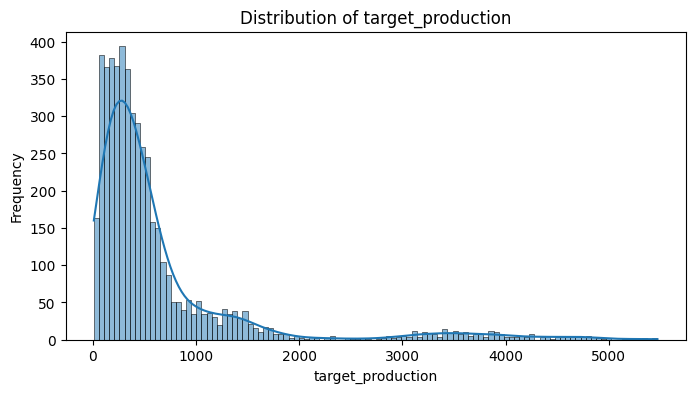

In [44]:
from scipy.stats import skew
import matplotlib.pyplot as plt
import seaborn as sns

# Columns to examine
columns_to_check = [
    'target_production',
    'Rainfall'
]

for col in columns_to_check:

    if col in feat_df.columns:

        values = feat_df[col].dropna()

        print(f"\n{col}")
        print("Skewness:", skew(values))

        plt.figure(figsize=(8, 4))
        sns.histplot(values, kde=True)
        plt.title(f"Distribution of {col}")
        plt.xlabel(col)
        plt.ylabel("Frequency")
        plt.show()

In [41]:
# Save complete feature-engineered dataset
feat_df.to_csv(
    'tea_feature_engineered_1month_ahead.csv',
    index=False
)

# Save weather-only modelling dataset
weather_model_df.to_csv(
    'tea_weather_only_model_dataset.csv',
    index=False
)

# Save weather + production modelling dataset
production_model_df.to_csv(
    'tea_weather_production_model_dataset.csv',
    index=False
)

print("All datasets saved successfully!")

All datasets saved successfully!


In [42]:
from google.colab import files

files.download('tea_feature_engineered_1month_ahead.csv')
files.download('tea_weather_only_model_dataset.csv')
files.download('tea_weather_production_model_dataset.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>